## 1. Import Necessary Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Data Collection

In [2]:
diabetes_dataset = load_diabetes(as_frame=True)

dataset = diabetes_dataset.frame

print("Dataset loaded successfully")
dataset.head()

Dataset loaded successfully


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019908,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068330,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005671,-0.045599,-0.034194,-0.032356,-0.002592,0.002864,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022692,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031991,-0.046641,135.0


## 3. Data Understanding

In [4]:
dataset.info()
dataset.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-3.639623e-16,1.309912e-16,-8.013951e-16,1.289818e-16,-9.042540e-17,1.301121e-16,-4.563971e-16,3.863174e-16,-3.848103e-16,-3.398488e-16,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123996e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260974e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665645e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324879e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670611e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947634e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564384e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243323e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320442e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335990e-01,1.356118e-01,346.000000


In [5]:
dataset.isnull().sum()

dataset.duplicated().sum()

0

## 4. Data Preparation

In [6]:
target_column = "target"


dataset = dataset.drop_duplicates()


X = dataset.drop(columns=[target_column])
y = dataset[target_column]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (442, 10)
Target shape: (442,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (353, 10)
Testing data shape: (89, 10)


## 5. Model Building – Linear Regression

In [9]:
linear_regression_model = LinearRegression()

linear_regression_model.fit(X_train, y_train)

LinearRegression()

## 6. Model Evaluation

In [11]:
y_pred = linear_regression_model.predict(X_test)


mean_absolute_error_value = mean_absolute_error(y_test, y_pred)
mean_squared_error_value = mean_squared_error(y_test, y_pred)
root_mean_squared_error = np.sqrt(mean_squared_error_value)
r2_score_value = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mean_absolute_error_value)
print("Mean Squared Error (MSE):", mean_squared_error_value)
print("Root Mean Squared Error (RMSE):", root_mean_squared_error)
print("R2 Score:", r2_score_value)

Mean Absolute Error (MAE): 42.793893041965255
Mean Squared Error (MSE): 2900.173287883232
Root Mean Squared Error (RMSE): 53.8532569849144
R2 Score: 0.45260660216173787


## 7. Model Testing

In [13]:
testing_results = pd.DataFrame({"Actual Value": y_test.values,"Predicted Value": y_pred})

testing_results["Difference"] = (testing_results["Actual Value"] - testing_results["Predicted Value"])

testing_results.head(10)

,Actual Value,Predicted Value,Difference
0,219.0,139.548313,79.451687
1,70.0,179.520306,-109.520306
2,202.0,134.041333,67.958667
3,230.0,291.411936,-61.411936
4,111.0,123.787237,-12.787237
5,84.0,92.173577,-8.173577
6,242.0,258.234097,-16.234097
7,272.0,181.338952,90.661048
8,94.0,90.222179,3.777821
9,96.0,108.631433,-12.631433


## 8. Visualize Actual vs Predicted Values

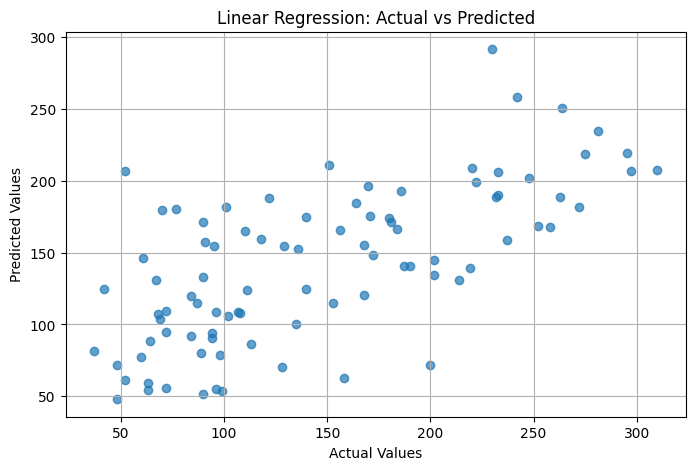

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()

## 9. Test with New Input Data

In [15]:
new_input = X_test.iloc[[0]]

final_prediction = linear_regression_model.predict(new_input)

print("Input values:")
print(new_input)

print("\\nPredicted value:", final_prediction[0])
print("Actual value:", y_test.iloc[0])

Input values:
          age       sex       bmi        bp        s1        s2        s3  \
287  0.045341 -0.044642 -0.006206 -0.015999  0.125019  0.125198  0.019187   

           s4        s5       s6  
287  0.034309  0.032433 -0.00522  
\nPredicted value: 139.54831330342864
Actual value: 219.0
